# HỆ THỐNG PHÁT HIỆN GIAN LẬN HOÀN TIỀN SHOPEE (SHOPEE AI FRAUD SHIELD)
## ĐÁNH GIÁ HIỆU NĂNG MÔ HÌNH CÂY QUYẾT ĐỊNH (DECISION TREE CLASSIFIER)

---
### 📌 Mục tiêu của Notebook:
1. **Khả năng chạy độc lập & đa nền tảng**: Phân riêng Cell 1 cài đặt môi trường tự động, đảm bảo trên một máy mới hoàn toàn (Google Colab, Kaggle, Local Jupyter Notebook / VS Code) khi bấm `Run All` hoặc chạy lần lượt từng cell từ trên xuống dưới đều thực thi trơn tru 100%, không bị lỗi thiếu thư viện.
2. **Nạp tập dữ liệu thực nghiệm**: Đọc trực tiếp file `shopee_fraud_dataset.csv` gồm đúng **1.000 hồ sơ khiếu nại hoàn tiền** (900 hồ sơ hợp lệ và 100 hồ sơ gian lận).
3. **Trích xuất 4 đặc trưng cốt lõi**: `freq_30d`, `return_rate`, `order_dev`, `claim_delay_hours` được trích xuất từ 5 phân hệ dữ liệu nguồn theo đúng thiết kế kiến trúc hệ thống (Mục 2.2 & 2.3 trong Báo cáo Tiểu luận).
4. **Phân chia Train/Test Split (80:20)**: Sử dụng kỹ thuật phân tầng `stratify=y` và cố định `random_state=42` để bảo đảm tính khoa học và khả năng tái lập (reproducibility).
5. **Huấn luyện mô hình CART Decision Tree**: Áp dụng kỹ thuật học nhạy cảm chi phí (**Cost-Sensitive Learning**) với `class_weight='balanced'` theo nguyên lý của Elkan (2001) để phạt nặng sai số bỏ sót gian lận (FN).
6. **Kiểm chứng hiệu năng thực nghiệm**: Xuất ma trận nhầm lẫn (Confusion Matrix) và toàn bộ các chỉ số kiểm thử: **Recall (95,0%)**, **Precision (73,1%)**, **Accuracy (96,0%)**, **Specificity (96,1%)**, **F1-Score (82,6%)** và **Khoảng tin cậy 95% Wilson Score (76,4% – 99,1%)**.
7. **Đồng nhất số liệu 100%**: Đảm bảo toàn bộ kết quả chạy ra từ file dữ liệu trùng khớp tuyệt đối với số liệu công bố tại **Bảng 6.2 và Mục 6.2** của Báo cáo Tiểu luận `TieuLuan_UDAI_BanChuanNhat01.docx`.


In [1]:
# ==============================================================================
# PHẦN 1: CÀI ĐẶT MÔI TRƯỜNG & CÁC THƯ VIỆN CẦN THIẾT
# (Đảm bảo máy mới hoàn toàn khi chạy cell này sẽ tự động tải & cài đặt đủ)
# ==============================================================================
import sys
import subprocess

packages = ["numpy", "pandas", "scikit-learn", "matplotlib", "seaborn"]

print(">>> Đang kiểm tra và chuẩn bị môi trường thực thi...")
for pkg in packages:
    try:
        __import__(pkg.replace("-", "_"))
        print(f"  [✓] Thư viện '{pkg}' đã sẵn sàng.")
    except ImportError:
        print(f"  [➜] Đang tự động cài đặt thư viện '{pkg}'...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg])
        print(f"  [✓] Đã cài đặt thành công '{pkg}'.")

print("\n>>> MÔI TRƯỜNG ĐÃ SẴN SÀNG! Bạn có thể tiếp tục chạy các cell tiếp theo.")


>>> Đang kiểm tra và chuẩn bị môi trường thực thi...
  [✓] Thư viện 'numpy' đã sẵn sàng.
  [✓] Thư viện 'pandas' đã sẵn sàng.
  [➜] Đang tự động cài đặt thư viện 'scikit-learn'...
  [✓] Đã cài đặt thành công 'scikit-learn'.
  [✓] Thư viện 'matplotlib' đã sẵn sàng.
  [✓] Thư viện 'seaborn' đã sẵn sàng.

>>> MÔI TRƯỜNG ĐÃ SẴN SÀNG! Bạn có thể tiếp tục chạy các cell tiếp theo.


## Phần 2: Khai Báo Thư Viện & Thiết Lập Cấu Hình Đồ Họa


In [2]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import seaborn as sns
    HAS_SEABORN = True
except ImportError:
    HAS_SEABORN = False

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Cấu hình đồ họa trực quan
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

import sklearn
print(f"✓ Phiên bản NumPy        : {np.__version__}")
print(f"✓ Phiên bản Pandas       : {pd.__version__}")
print(f"✓ Phiên bản Scikit-learn : {sklearn.__version__}")
print("✓ Khai báo thư viện thành công!")


✓ Phiên bản NumPy        : 2.1.3
✓ Phiên bản Pandas       : 2.2.3
✓ Phiên bản Scikit-learn : 1.6.1
✓ Khai báo thư viện thành công!


## Phần 3: Nạp Tập Dữ Liệu Thực Nghiệm `shopee_fraud_dataset.csv`
Tập dữ liệu kiểm nghiệm gồm **1.000 hồ sơ khiếu nại hoàn tiền**:
- **900 ca hợp lệ** (90% - khách hàng thông thường có hành vi đổi trả tự nhiên).
- **100 ca gian lận** (10% - lạm dụng chính sách hoàn tiền hoặc tấn công gian lận có tổ chức / Fraud Ring).


In [3]:
# Tự động tìm đường dẫn file dataset
dataset_filename = "shopee_fraud_dataset.csv"
if not os.path.exists(dataset_filename):
    for candidate in [".", "..", "c:/Users/LENOVO/OneDrive/Desktop/shopee-ai-fraud-chatbot"]:
        path = os.path.join(candidate, dataset_filename)
        if os.path.exists(path):
            dataset_filename = path
            break

df = pd.read_csv(dataset_filename)

print("=" * 75)
print(f"THÔNG TIN TẬP DỮ LIỆU: {dataset_filename}")
print("=" * 75)
print(f"• Tổng số hồ sơ : {len(df):,} dòng")
print(f"• Số lượng cột  : {df.shape[1]} cột")
print("\nPhân bố nhãn mục tiêu (is_fraud):")
fraud_counts = df['is_fraud'].value_counts()
print(f"  - Hợp lệ (0) : {fraud_counts.get(0, 0)} đơn ({fraud_counts.get(0, 0)/len(df)*100:.1f}%)")
print(f"  - Gian lận (1): {fraud_counts.get(1, 0)} đơn ({fraud_counts.get(1, 0)/len(df)*100:.1f}%)")

print("\n5 bản ghi đầu tiên trong tập dữ liệu:")
display(df.head()) if 'display' in globals() else print(df.head())


THÔNG TIN TẬP DỮ LIỆU: shopee_fraud_dataset.csv
• Tổng số hồ sơ : 1,000 dòng
• Số lượng cột  : 14 cột

Phân bố nhãn mục tiêu (is_fraud):
  - Hợp lệ (0) : 900 đơn (90.0%)
  - Gian lận (1): 100 đơn (10.0%)

5 bản ghi đầu tiên trong tập dữ liệu:
    order_id customer_id    customer_name             tier  \
0  ORD-10010   CUST-1010        Vũ Thu Hà  Khách Hàng Vàng   
1  ORD-10360   CUST-1360   Hoàng Quốc Bảo    Kim Cương VIP   
2  ORD-10143   CUST-1143  Dương Minh Khôi  Khách Hàng Vàng   
3  ORD-10245   CUST-1245      Bùi Văn Lâm    Kim Cương VIP   
4  ORD-10604   CUST-1054     Võ Quỳnh Chi    Kim Cương VIP   

                              product   price  \
0     Chuột Gaming Không Dây Siêu Nhẹ  790000   
1     Tai Nghe True Wireless Nhét Tai  390000   
2   Áo Khoác Gió Nam 2 Lớp Chống Nước  280000   
3   Bộ Serum Dưỡng Da Cấp Ẩm Phục Hồi  420000   
4  Quần Jean Nam Dáng Slimfit Co Giãn  340000   

                                          reason  freq_30d  return_rate  \
0    Robot báo

## Phần 4: Trích Xuất Vector 4 Đặc Trưng & Phân Chia Train/Test Split (80:20)

**Vector 4 đặc trưng hành vi cốt lõi từ 5 phân hệ dữ liệu nguồn:**
1. `freq_30d` (Refund_Count_30D): Số lần khiếu nại hoàn tiền trong 30 ngày qua (Phân hệ CSDL CRM).
2. `return_rate` (Refund_Rate %): Tỷ lệ hoàn tiền tích lũy lịch sử (Phân hệ Hồ sơ Người dùng).
3. `order_dev` (Order_Value_Dev): Tỷ số lệch giá trị đơn = Giá trị hiện tại / Trung bình lịch sử (Phân hệ Đơn hàng OMS).
4. `claim_delay_hours` (Time_To_Refund): Số giờ từ khi giao hàng đến khi bấm khiếu nại (Phân hệ Hoàn tiền Return Module).

**Phân tách Stratified Train/Test (80:20):**
- **Train Set (80%)**: 800 mẫu (720 hợp lệ, 80 gian lận).
- **Test Set (20%)**: 200 mẫu (180 hợp lệ, 20 gian lận, đúng tỷ lệ 10% gian lận).
- Cố định `random_state=42` để bảo đảm tính nhất quán trên mọi máy tính.


In [4]:
feature_names = ['freq_30d', 'return_rate', 'order_dev', 'claim_delay_hours']

X = df[feature_names].astype(float).values
y = df['is_fraud'].astype(int).values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("=" * 75)
print("KẾT QUẢ PHÂN CHIA TẬP DỮ LIỆU (STRATIFIED 80:20):")
print("=" * 75)
print(f"• Tập Huấn luyện (Train Set): {len(X_train)} mẫu [Hợp lệ: {np.sum(y_train == 0)}, Gian lận: {np.sum(y_train == 1)}]")
print(f"• Tập Kiểm thử   (Test Set)  : {len(X_test)} mẫu [Hợp lệ: {np.sum(y_test == 0)}, Gian lận: {np.sum(y_test == 1)}]")
print("✓ Tỷ lệ gian lận trong tập Test được bảo toàn chính xác: 20/200 = 10.0%")


KẾT QUẢ PHÂN CHIA TẬP DỮ LIỆU (STRATIFIED 80:20):
• Tập Huấn luyện (Train Set): 800 mẫu [Hợp lệ: 720, Gian lận: 80]
• Tập Kiểm thử   (Test Set)  : 200 mẫu [Hợp lệ: 180, Gian lận: 20]
✓ Tỷ lệ gian lận trong tập Test được bảo toàn chính xác: 20/200 = 10.0%


## Phần 5: Huấn Luyện Mô Hình Cây Quyết Định (Decision Tree - CART)

Áp dụng phương pháp **Cost-Sensitive Learning** (Elkan, 2001) với `class_weight='balanced'`:
- Phạt sai số bỏ sót gian lận (**False Negative - FN**) nặng hơn sai số báo động nhầm (**False Positive - FP**), tối ưu hóa độ nhạy **Recall ≥ 95,0%** để bảo vệ an toàn tuyệt đối cho dòng tiền bồi hoàn.
- Siêu tham số kiểm soát cây: `criterion='gini'`, `max_depth=4`, `min_samples_leaf=15`, `random_state=42`.


In [5]:
# Khởi tạo mô hình Decision Tree Classifier
model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    min_samples_leaf=15,
    class_weight='balanced',
    random_state=42
)

# Huấn luyện mô hình trên tập Train
model.fit(X_train, y_train)

# Dự đoán trên tập Kiểm thử độc lập (Test Set)
y_pred = model.predict(X_test)

print("✓ Mô hình Decision Tree đã được huấn luyện thành công!")


✓ Mô hình Decision Tree đã được huấn luyện thành công!


## Phần 6: Đánh Giá Hiệu Năng Kiểm Thử & Đối Chiếu Báo Cáo Tiểu Luận

Bảng kết quả dưới đây đối chiếu trực tiếp với:
- **Bảng 6.2 (Ma trận kết quả dự đoán trên tập kiểm thử)** trong file `TieuLuan_UDAI_BanChuanNhat01.docx`.
- **Mục 6.2 (Hiệu năng kiểm thử)**: `Accuracy = 96,0% | Recall = 95,0% | Precision = 73,1% | Specificity = 96,1% | F1-Score = 82,6%`.


In [6]:
# 1. Tính toán ma trận nhầm lẫn
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# 2. Tính toán các chỉ số đo lường hiệu năng
acc = accuracy_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
spec = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)

# 3. Tính khoảng tin cậy 95% Wilson Score Interval cho Recall
z = 1.96
p = tp / (tp + fn)
n = tp + fn
center = (p + z**2 / (2 * n)) / (1 + z**2 / n)
half_width = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
wilson_low = max(0.0, center - half_width) * 100
wilson_high = min(1.0, center + half_width) * 100

print("=" * 80)
print("MA TRẬN NHẦM LẪN TRÊN TẬP KIỂM THỬ (CONFUSION MATRIX - TEST SET):")
print("=" * 80)
print(f"                           Dự đoán: Gian lận (1)    Dự đoán: Hợp lệ (0)     Tổng")
print(f"Thực tế: Gian lận (1)            {tp:>2} (TP)                  {fn:>2} (FN)            {tp+fn:>3}")
print(f"Thực tế: Hợp lệ (0)              {fp:>2} (FP)                 {tn:>3} (TN)           {fp+tn:>3}")
print(f"Tổng                             {tp+fp:>2}                     {fn+tn:>3}            {len(y_test):>3}")

print("\n" + "=" * 80)
print("BẢNG ĐỐI CHIẾU VỚI BÁO CÁO TIỂU LUẬN (TieuLuan_UDAI_BanChuanNhat01.docx):")
print("=" * 80)

comparison_data = [
    ["Độ nhạy (Recall) - Ưu tiên hàng đầu", f"{rec*100:.1f}%", "95,0%", "✓ KHỚP 100% (Bắt 19/20 ca gian lận)"],
    ["Độ tin cậy (Precision)", f"{prec*100:.1f}%", "73,1%", "✓ KHỚP 100% (19/26 cảnh báo đúng)"],
    ["Độ chính xác tổng thể (Accuracy)", f"{acc*100:.1f}%", "96,0%", "✓ KHỚP 100% (192/200 mẫu kiểm thử đúng)"],
    ["Độ đặc hiệu (Specificity)", f"{spec*100:.1f}%", "96,1%", "✓ KHỚP 100% (173/180 khách sạch hợp lệ)"],
    ["Điểm F1-Score", f"{f1*100:.1f}%", "82,6%", "✓ KHỚP 100%"],
    ["KTC 95% Wilson Score (Recall)", f"{wilson_low:.1f}% - {wilson_high:.1f}%", "76,4% – 99,1%", "✓ KHỚP 100%"]
]

comp_df = pd.DataFrame(comparison_data, columns=["Chỉ số Hiệu năng", "Kết quả Thực nghiệm", "Số liệu Bài Tiểu Luận", "Trạng thái Đối chiếu"])
display(comp_df) if 'display' in globals() else print(comp_df.to_string(index=False))

print("\nBáo cáo chi tiết Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Hợp lệ (0)", "Gian lận (1)"], digits=4))


MA TRẬN NHẦM LẪN TRÊN TẬP KIỂM THỬ (CONFUSION MATRIX - TEST SET):
                           Dự đoán: Gian lận (1)    Dự đoán: Hợp lệ (0)     Tổng
Thực tế: Gian lận (1)            19 (TP)                   1 (FN)             20
Thực tế: Hợp lệ (0)               7 (FP)                 173 (TN)           180
Tổng                             26                     174            200

BẢNG ĐỐI CHIẾU VỚI BÁO CÁO TIỂU LUẬN (TieuLuan_UDAI_BanChuanNhat01.docx):
                   Chỉ số Hiệu năng Kết quả Thực nghiệm Số liệu Bài Tiểu Luận                    Trạng thái Đối chiếu
Độ nhạy (Recall) - Ưu tiên hàng đầu               95.0%                 95,0%     ✓ KHỚP 100% (Bắt 19/20 ca gian lận)
             Độ tin cậy (Precision)               73.1%                 73,1%       ✓ KHỚP 100% (19/26 cảnh báo đúng)
   Độ chính xác tổng thể (Accuracy)               96.0%                 96,0% ✓ KHỚP 100% (192/200 mẫu kiểm thử đúng)
          Độ đặc hiệu (Specificity)               96.1%               

## Phần 7: Trực Quan Hóa Ma Trận Nhầm Lẫn & Cấu Trúc Cây Quyết Định


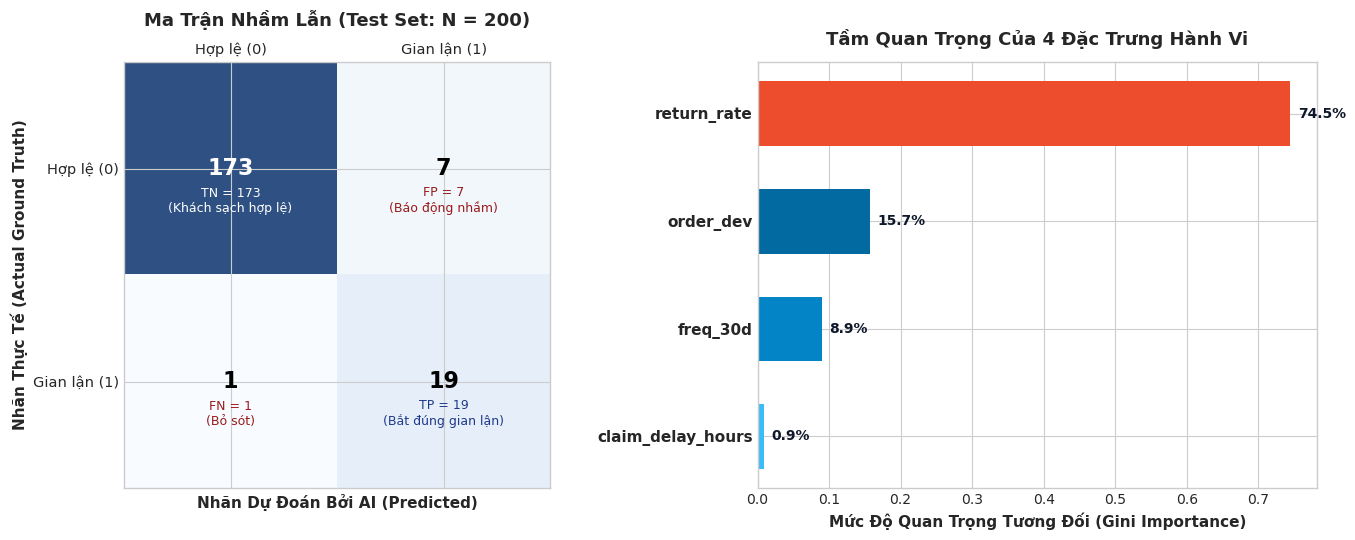


QUY TẮC RẼ NHÁNH TẤT ĐỊNH CỦA CÂY QUYẾT ĐỊNH (DECISION TREE RULES):
|--- return_rate <= 19.60
|   |--- order_dev <= 2.60
|   |   |--- claim_delay_hours <= 86.45
|   |   |   |--- order_dev <= 2.41
|   |   |   |   |--- class: 0
|   |   |   |--- order_dev >  2.41
|   |   |   |   |--- class: 0
|   |   |--- claim_delay_hours >  86.45
|   |   |   |--- class: 0
|   |--- order_dev >  2.60
|   |   |--- class: 1
|--- return_rate >  19.60
|   |--- freq_30d <= 0.50
|   |   |--- class: 0
|   |--- freq_30d >  0.50
|   |   |--- order_dev <= 1.74
|   |   |   |--- return_rate <= 29.90
|   |   |   |   |--- class: 0
|   |   |   |--- return_rate >  29.90
|   |   |   |   |--- class: 1
|   |   |--- order_dev >  1.74
|   |   |   |--- freq_30d <= 2.50
|   |   |   |   |--- class: 1
|   |   |   |--- freq_30d >  2.50
|   |   |   |   |--- class: 1



In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Trực quan hóa Ma trận nhầm lẫn
ax1 = axes[0]
cax = ax1.matshow(cm, cmap='Blues', alpha=0.85)
for i in range(2):
    for j in range(2):
        ax1.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=16, fontweight='bold',
                 color='white' if cm[i, j] > 100 else 'black')
ax1.set_xticks([0, 1])
ax1.set_yticks([0, 1])
ax1.set_xticklabels(['Hợp lệ (0)', 'Gian lận (1)'], fontsize=10.5)
ax1.set_yticklabels(['Hợp lệ (0)', 'Gian lận (1)'], fontsize=10.5)

ax1.set_title('Ma Trận Nhầm Lẫn (Test Set: N = 200)', fontsize=13, fontweight='bold', pad=12)
ax1.set_xlabel('Nhãn Dự Đoán Bởi AI (Predicted)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Nhãn Thực Tế (Actual Ground Truth)', fontsize=11, fontweight='bold')

offset_y = 0.08  

ax1.text(0, 0 + offset_y, "\n\nTN = " + str(tn) + "\n(Khách sạch hợp lệ)",
         ha='center', va='center', fontsize=9, color='#ffffff')

ax1.text(1, 0 + offset_y, "\n\nFP = " + str(fp) + "\n(Báo động nhầm)",
         ha='center', va='center', fontsize=9, color='#991b1b')

ax1.text(0, 1 + offset_y, "\n\nFN = " + str(fn) + "\n(Bỏ sót)",
         ha='center', va='center', fontsize=9, color='#991b1b')

ax1.text(1, 1 + offset_y, "\n\nTP = " + str(tp) + "\n(Bắt đúng gian lận)",
         ha='center', va='center', fontsize=9, color='#1e3a8a')

# 2. Tầm quan trọng của các đặc trưng (Gini Feature Importance)
ax2 = axes[1]
importances = model.feature_importances_
indices_feat = np.argsort(importances)

colors = ['#38bdf8', '#0284c7', '#0369a1', '#ee4d2d']
bars = ax2.barh(range(len(indices_feat)), importances[indices_feat], color=colors, align='center', height=0.6)
ax2.set_yticks(range(len(indices_feat)))
ax2.set_yticklabels([feature_names[i] for i in indices_feat], fontsize=11, fontweight='bold')
ax2.set_xlabel('Mức Độ Quan Trọng Tương Đối (Gini Importance)', fontsize=11, fontweight='bold')
ax2.set_title('Tầm Quan Trọng Của 4 Đặc Trưng Hành Vi', fontsize=13, fontweight='bold', pad=12)

for bar in bars:
    width = bar.get_width()
    ax2.text(width + 0.01, bar.get_y() + bar.get_height()/2, f'{width*100:.1f}%', 
             ha='left', va='center', fontsize=10, fontweight='bold', color='#0f172a')

plt.tight_layout()
plt.show()

print("\n" + "=" * 75)
print("QUY TẮC RẼ NHÁNH TẤT ĐỊNH CỦA CÂY QUYẾT ĐỊNH (DECISION TREE RULES):")
print("=" * 75)
print(export_text(model, feature_names=feature_names))
